# 1. Introduction

Linear Regression is a supervised machine learning algorithm used to predict a continuous numerical value based on one or more input variables.

In this notebook, we will use Linear Regression to predict car prices based on different car features.

Project Objectives

- Understand the fundamentals of Regression and Linear Regression.
- Understand Simple and Multiple Linear Regression.
- Identify independent and dependent variables.
- Understand coefficients and intercept.
- Perform predictions using Scikit-learn.
- Analyze residuals and the least squares method.
- Understand the cost function and Gradient Descent.
- Implement Linear Regression mathematics using NumPy.
- Evaluate model performance using regression metrics.

# 2. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42

print("Libraries imported successfully.")

Libraries imported successfully.


# 3. Load Dataset

The Car Price Prediction dataset contains information about different cars, including their brand, manufacturing year, engine size, mileage, fuel type, transmission, condition, and price.

The target variable is Price.

In [4]:
car_df = pd.read_csv(r"datasets/car_prediction/car_price_prediction_.csv")

print("Dataset loaded successfully.")
car_df.head()

Dataset loaded successfully.


,Car ID,Brand,Year,Engine Size,Fuel Type,Transmission,Mileage,Condition,Price,Model
0,1,Tesla,2016,2.3,Petrol,Manual,114832,New,26613.92,Model X
1,2,BMW,2018,4.4,Electric,Manual,143190,Used,14679.61,5 Series
2,3,Audi,2013,4.5,Electric,Manual,181601,New,44402.61,A4
3,4,Tesla,2011,4.1,Diesel,Automatic,68682,New,86374.33,Model Y
4,5,Ford,2009,2.6,Diesel,Manual,223009,Like New,73577.10,Mustang


# 4. Dataset Overview

Dataset overview helps us understand the number of records, columns, data types, and structure of the dataset.

In [5]:
print("Dataset Shape:", car_df.shape)

print("\nColumn Names:")
print(car_df.columns.tolist())

print("\nDataset Information:")
car_df.info()

Dataset Shape: (2500, 10)

Column Names:
['Car ID', 'Brand', 'Year', 'Engine Size', 'Fuel Type', 'Transmission', 'Mileage', 'Condition', 'Price', 'Model']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2500 entries, 0 to 2499
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Car ID        2500 non-null   int64  
 1   Brand         2500 non-null   object 
 2   Year          2500 non-null   int64  
 3   Engine Size   2500 non-null   float64
 4   Fuel Type     2500 non-null   object 
 5   Transmission  2500 non-null   object 
 6   Mileage       2500 non-null   int64  
 7   Condition     2500 non-null   object 
 8   Price         2500 non-null   float64
 9   Model         2500 non-null   object 
dtypes: float64(2), int64(3), object(5)
memory usage: 195.4+ KB


In [6]:
car_df.describe()

,Car ID,Year,Engine Size,Mileage,Price
count,2500.00000,2500.0000,2500.000000,2500.000000,2500.000000
mean,1250.50000,2011.6268,3.465240,149749.844800,52638.022532
std,721.83216,6.9917,1.432053,87919.952034,27295.833455
min,1.00000,2000.0000,1.000000,15.000000,5011.270000
25%,625.75000,2005.0000,2.200000,71831.500000,28908.485000
50%,1250.50000,2012.0000,3.400000,149085.000000,53485.240000
75%,1875.25000,2018.0000,4.700000,225990.500000,75838.532500
max,2500.00000,2023.0000,6.000000,299967.000000,99982.590000


# 5. Data Understanding

Before building a Linear Regression model, we inspect the dataset to understand its numerical features and check for missing values.

In [7]:
print("Missing Values:")
print(car_df.isnull().sum())

print("\nDuplicate Rows:", car_df.duplicated().sum())

print("\nNumerical Columns:")
print(car_df.select_dtypes(include=np.number).columns.tolist())

Missing Values:
Car ID          0
Brand           0
Year            0
Engine Size     0
Fuel Type       0
Transmission    0
Mileage         0
Condition       0
Price           0
Model           0
dtype: int64

Duplicate Rows: 0

Numerical Columns:
['Car ID', 'Year', 'Engine Size', 'Mileage', 'Price']


# 6. Independent and Dependent Variables

In machine learning, variables are divided into independent and dependent variables.
- Independent Variables (X): Input features used to make predictions.
- Dependent Variable (y): The output value that the model tries to predict.

For this car price prediction problem:
- Independent variables: Year, Engine Size, Mileage.
- Dependent variable: Price.

In [8]:
X = car_df[["Year", "Engine Size", "Mileage"]]
y = car_df["Price"]

print("Independent Variables:")
display(X.head())

print("Dependent Variable:")
display(y.head())

Independent Variables:


,Year,Engine Size,Mileage
0,2016,2.3,114832
1,2018,4.4,143190
2,2013,4.5,181601
3,2011,4.1,68682
4,2009,2.6,223009


Dependent Variable:


0    26613.92
1    14679.61
2    44402.61
3    86374.33
4    73577.10
Name: Price, dtype: float64

# 7. What is Regression?

Regression is a supervised machine learning technique used to predict continuous numerical values.

Examples:
- Car price prediction.
- House price prediction.

Regression models identify relationships between input variables and a numerical output.

Types of Regression

    1. Simple Linear Regression
    2. Multiple Linear Regression
    3. Polynomial Regression
    4. Ridge Regression
    5. Lasso Regression


# 8. What is Linear Regression?

Linear Regression is a supervised learning algorithm that models the relationship between independent variables and a dependent variable using a straight line.

It finds the best-fitting line that minimizes the difference between actual and predicted values.

Equation of Linear Regression:

[y = mx + c]

Where:
- (y) = Predicted value.
- (x) = Input variable.
- (m) = Slope or coefficient.
- (c) = Intercept.

# 9. Equation of a Line

The equation of a straight line describes the relationship between input and output values.
[y = mx + c]

- Slope (m): Indicates how much the predicted value changes when the input increases by one unit.
- Intercept (c): The predicted value when the input variable is zero.

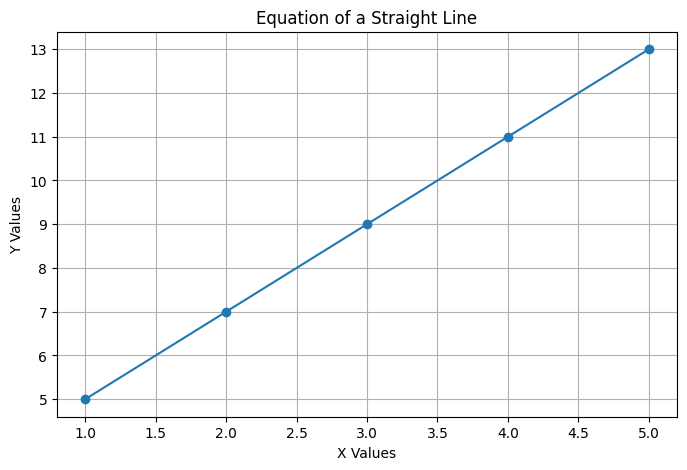

In [9]:
x = np.array([1, 2, 3, 4, 5])
y = 2 * x + 3

plt.figure(figsize=(8, 5))
plt.plot(x, y, marker="o")

plt.xlabel("X Values")
plt.ylabel("Y Values")
plt.title("Equation of a Straight Line")

plt.grid(True)
plt.show()

# 10. Simple Linear Regression

Simple Linear Regression uses only one independent variable to predict one dependent variable.

For our car price prediction:
- Independent variable: Engine Size.
- Dependent variable: Price.

The model learns the relationship between engine size and car price.

In [10]:
X_simple = car_df[["Engine Size"]]
y_simple = car_df["Price"]

simple_data = pd.concat(
    [X_simple, y_simple],
    axis=1
).dropna()

X_simple = simple_data[["Engine Size"]]
y_simple = simple_data["Price"]

X_train_simple, X_test_simple, y_train_simple, y_test_simple = train_test_split(
    X_simple,
    y_simple,
    test_size=0.20,
    random_state=RANDOM_STATE
)

simple_model = LinearRegression()

simple_model.fit(X_train_simple, y_train_simple)

print("Simple Linear Regression model trained successfully.")

Simple Linear Regression model trained successfully.


# 11. Multiple Linear Regression

Multiple Linear Regression uses two or more independent variables to predict a dependent variable.

For our car price prediction:
- Year
- Engine Size
- Mileage

These three features are used to predict the car's price.

In [11]:
regression_data = car_df[
    ["Year", "Engine Size", "Mileage", "Price"]
].dropna()

X = regression_data[
    ["Year", "Engine Size", "Mileage"]
]

y = regression_data["Price"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE
)

multiple_model = LinearRegression()

multiple_model.fit(X_train, y_train)

print("Multiple Linear Regression model trained successfully.")
print("Training Data Shape:", X_train.shape)
print("Testing Data Shape:", X_test.shape)

Multiple Linear Regression model trained successfully.
Training Data Shape: (2000, 3)
Testing Data Shape: (500, 3)


# 12. Coefficients and Intercept

Coefficients and intercept are important parts of a Linear Regression model.

    -  Coefficient: Represents the change in the predicted price for a one-unit increase in a feature, 
       while keeping other features constant.
       
    -  Intercept: Represents the model's predicted price when all input features are zero.

In [12]:
print("Model Intercept:", multiple_model.intercept_)

coefficient_df = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": multiple_model.coef_
})

display(coefficient_df)

Model Intercept: 357969.61274519045


,Feature,Coefficient
0,Year,-151.538019
1,Engine Size,-125.125631
2,Mileage,-0.001655


# Interpretation

A positive coefficient indicates a positive relationship with predicted price, while a negative coefficient indicates a negative relationship, assuming other features remain constant.

# 13. Prediction

Prediction is the process of using a trained machine learning model to estimate the output for new input data.

Here, the trained Linear Regression model predicts car prices using Year, Engine Size, and Mileage.

In [13]:
y_pred = multiple_model.predict(X_test)

prediction_df = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

display(prediction_df.head(10))

,Actual Price,Predicted Price
0,17494.90,52652.127868
1,75919.94,51281.175058
2,87474.10,52293.596330
3,13522.58,53283.026133
4,77070.57,51668.609162
5,40085.49,50901.994324
6,47196.40,51504.370534
7,58558.94,52315.378540
8,23029.74,53013.095490
9,32351.06,52675.794496


# 14. Residuals

A residual is the difference between the actual value and the predicted value.
[Residual = Actual\ Value - Predicted\ Value]

Residuals help us understand how far the model's predictions are from the actual values.
- Positive residual: Actual value is greater than predicted value.
- Negative residual: Actual value is less than predicted value.
- Zero residual: Actual and predicted values are equal.

In [14]:
residuals = y_test.values - y_pred

residual_df = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred,
    "Residual": residuals
})

display(residual_df.head(10))

,Actual Price,Predicted Price,Residual
0,17494.90,52652.127868,-35157.227868
1,75919.94,51281.175058,24638.764942
2,87474.10,52293.596330,35180.503670
3,13522.58,53283.026133,-39760.446133
4,77070.57,51668.609162,25401.960838
5,40085.49,50901.994324,-10816.504324
6,47196.40,51504.370534,-4307.970534
7,58558.94,52315.378540,6243.561460
8,23029.74,53013.095490,-29983.355490
9,32351.06,52675.794496,-20324.734496



# 15. Least Squares Method

The Least Squares Method is used to find the best-fitting regression line.

It calculates the squared differences between actual and predicted values and selects the line with the smallest total squared error.


In [15]:
squared_errors = residuals ** 2

sse = np.sum(squared_errors)

print("Sum of Squared Errors (SSE):", sse)

Sum of Squared Errors (SSE): 378874766097.7964


Interpretation

A smaller SSE indicates that the predicted values are closer to the actual values for the evaluated observations. SSE alone should not be used to compare datasets of different sizes.

# 16. Cost Function

A cost function measures how much error a machine learning model makes while predicting values.

For Linear Regression, Mean Squared Error (MSE) is commonly used as a cost function.

In [16]:
mse_cost = np.mean((y_test.values - y_pred) ** 2)

print("Mean Squared Error Cost:", mse_cost)

Mean Squared Error Cost: 757749532.1955928


Interpretation

The cost function measures the average squared prediction error. A lower MSE indicates smaller average squared errors on the evaluated data.

# 17. Gradient Descent – Introduction

Gradient Descent is an optimization algorithm used to minimize the cost function in machine learning.

It repeatedly updates model parameters in the direction that reduces the prediction error.

Main Steps

    1. Initialize the model parameters.
    2. Calculate predictions.
    3. Calculate the cost function.
    4. Calculate gradients.
    5. Update coefficients and intercept.
    6. Repeat until the cost becomes smaller or the algorithm reaches its stopping condition.

# 18. Model Evaluation

Model evaluation helps measure how accurately the Linear Regression model predicts car prices.

We use the following regression metrics:

- MAE: Mean Absolute Error.
- MSE: Mean Squared Error.
- RMSE: Root Mean Squared Error.
- R² Score: Measures how much variation in the target is explained by the model.

In [17]:
mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

rmse = np.sqrt(mse)

r2 = r2_score(y_test, y_pred)

print("LINEAR REGRESSION MODEL EVALUATION")
print("----------------------------------")
print("MAE :", mae)
print("MSE :", mse)
print("RMSE:", rmse)
print("R2 Score:", r2)

LINEAR REGRESSION MODEL EVALUATION
----------------------------------
MAE : 23748.988610045424
MSE : 757749532.1955928
RMSE: 27527.250719888332
R2 Score: -0.0002589915499213724


# Interpretation
- Lower MAE, MSE, and RMSE indicate smaller prediction errors.
- An R² score closer to 1 indicates a better fit.
- A negative R² score means the model performs worse than predicting the average target value on the test data.

# 19. Actual vs Predicted Price Visualization

This visualization compares actual car prices with the prices predicted by the Linear Regression model.

If predictions are accurate, the points should be close to the diagonal reference line.

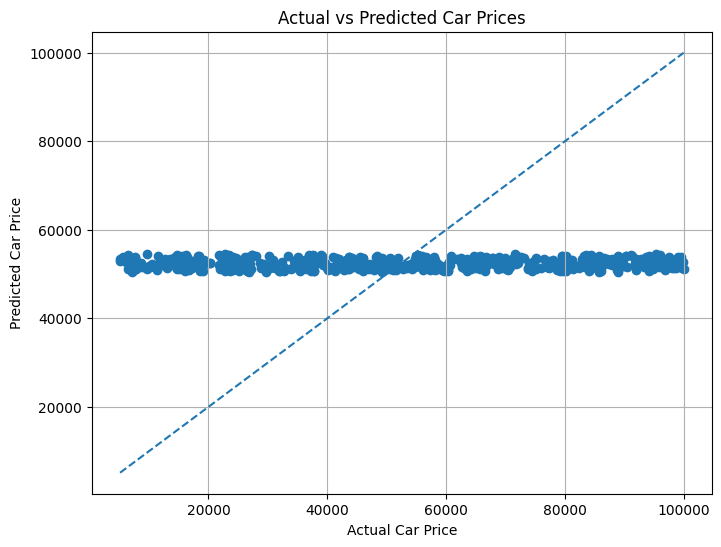

In [18]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred)

min_value = min(y_test.min(), y_pred.min())
max_value = max(y_test.max(), y_pred.max())

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.xlabel("Actual Car Price")
plt.ylabel("Predicted Car Price")
plt.title("Actual vs Predicted Car Prices")

plt.grid(True)
plt.show()

# 20. Simple Linear Regression Using NumPy

In this section, we implement Simple Linear Regression using NumPy without using Scikit-learn.

This helps us understand the mathematical calculations behind Linear Regression.

We use:
- Input variable (X): Engine Size.
- Output variable (Y): Car Price.

In [19]:
# Select Engine Size and Price
numpy_data = car_df[
    ["Engine Size", "Price"]
].dropna()

x = numpy_data["Engine Size"].to_numpy()
y_numpy = numpy_data["Price"].to_numpy()

# Calculate means
x_mean = np.mean(x)
y_mean = np.mean(y_numpy)

# Calculate slope
numerator = np.sum(
    (x - x_mean) * (y_numpy - y_mean)
)

denominator = np.sum(
    (x - x_mean) ** 2
)

slope = numerator / denominator

# Calculate intercept
intercept = y_mean - slope * x_mean

# Calculate predictions
y_numpy_pred = slope * x + intercept

print("NUMPY LINEAR REGRESSION")
print("-----------------------")
print("Slope:", slope)
print("Intercept:", intercept)

print("\nFirst 10 Predicted Prices:")
print(y_numpy_pred[:10])

NUMPY LINEAR REGRESSION
-----------------------
Slope: -84.2523016548026
Intercept: 52929.97697778629

First 10 Predicted Prices:
[52736.19668398 52559.26685051 52550.84162034 52584.542541
 52710.92099348 52727.77145381 52592.96777117 52483.43977902
 52449.73885835 52803.5985253 ]


# Interpretation

NumPy calculates the slope and intercept using mathematical formulas. These values define the best-fitting straight line for the selected data.

The predictions are calculated using the equation of a line.

# 21. NumPy Regression Visualization

This graph displays the actual car price observations and the regression line calculated using NumPy.

It helps us visually understand how the regression line represents the relationship between engine size and car price.

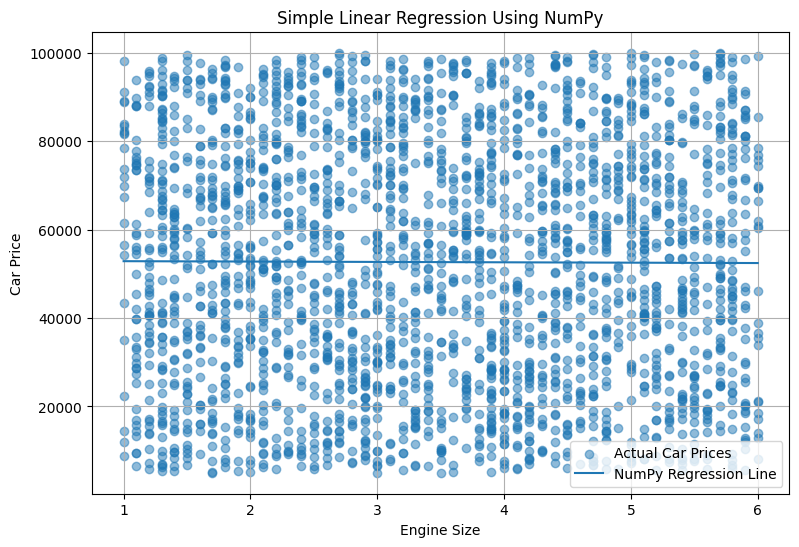

In [20]:
plt.figure(figsize=(9, 6))

plt.scatter(
    x,
    y_numpy,
    alpha=0.5,
    label="Actual Car Prices"
)

sorted_indices = np.argsort(x)

plt.plot(
    x[sorted_indices],
    y_numpy_pred[sorted_indices],
    label="NumPy Regression Line"
)

plt.xlabel("Engine Size")
plt.ylabel("Car Price")
plt.title("Simple Linear Regression Using NumPy")

plt.legend()
plt.grid(True)
plt.show()

# 22. Simple Linear Regression Using Scikit-learn – Evaluation

In this section, we evaluate the Simple Linear Regression model using Engine Size as the only independent variable.

This helps us understand the difference between Simple and Multiple Linear Regression.

In [21]:
simple_predictions = simple_model.predict(X_test_simple)

simple_mae = mean_absolute_error(
    y_test_simple,
    simple_predictions
)

simple_rmse = np.sqrt(
    mean_squared_error(y_test_simple, simple_predictions)
)

simple_r2 = r2_score(
    y_test_simple,
    simple_predictions
)

print("SIMPLE LINEAR REGRESSION RESULTS")
print("--------------------------------")
print("MAE:", simple_mae)
print("RMSE:", simple_rmse)
print("R2 Score:", simple_r2)

SIMPLE LINEAR REGRESSION RESULTS
--------------------------------
MAE: 23796.58549724824
RMSE: 27539.80873179721
R2 Score: -0.0011718418522177476


# 23. Conclusion

In this notebook, Linear Regression was implemented using the Car Price Prediction dataset.

The following concepts and practical implementations were completed:
- Understood Regression and Linear Regression.
- Learned Simple Linear Regression and Multiple Linear Regression.
- Identified independent and dependent variables.
- Understood the equation of a line, coefficients, and intercept.
- Trained Linear Regression models using Scikit-learn.
- Performed car price predictions.
- Calculated residuals and Sum of Squared Errors.
- Understood the cost function and Gradient Descent.
- Evaluated model performance using MAE, MSE, RMSE, and R² Score.
- Implemented Simple Linear Regression mathematics using NumPy.
- Visualized actual prices, predicted prices, and the regression line.

Final Conclusion:

Linear Regression helps understand relationships between numerical variables and predict continuous values. Scikit-learn makes model implementation easier, while NumPy helps us understand the mathematical calculations behind the algorithm.